<a href="https://colab.research.google.com/github/Dewanggieee/Analisis-Pola-Penyebaran-COVID-19-di-Indonesia-Menggunakan-Moran-s-I-dan-Spatial-Clustering/blob/main/FINAL_PROJECT_UAS_DATA_MINING_KELOMPOK_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Analisis Pola Penyebaran COVID-19 di Indonesia Menggunakan Moran’s I dan Spatial Clustering**
 Anggota Kelompok
1. Dewanggi Erchinta Dwi Putri (24031554034),
3. Nuri Maulidyatul Haliza (24031554160),
2. Naila Alya Furqon (24031554069)


Dosen Pengampu :Ulfa Siti Nuraini, S.Stat., M.Stat. dan Siska Puspitaningsih, S.Kom., M.Kom.

Kelas 2024B

Kelompok 2


# Load Dataset

Link Dataset :  https://www.kaggle.com/datasets/hendratno/covid19-indonesia

In [ ]:
!pip install splot
!pip install pandas geopandas pysal libpysal esda matplotlib
!pip install seaborn
!pip install mgwr

In [ ]:
from sklearn.preprocessing import StandardScaler
from mgwr.gwr import GWR
from mgwr.sel_bw import Sel_BW
from shapely.geometry import Point
from libpysal.weights import KNN
from esda.moran import Moran
from esda.moran import Moran_Local
from splot.esda import moran_scatterplot
from splot.esda import plot_moran
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import geopandas as gpd
import matplotlib.pyplot as plt

In [ ]:
!wget https://raw.githubusercontent.com/ans-4175/peta-indonesia-geojson/master/indonesia-prov.geojson

--2026-06-03 15:49:33--  https://raw.githubusercontent.com/ans-4175/peta-indonesia-geojson/master/indonesia-prov.geojson
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 728012 (711K) [text/plain]
Saving to: ‘indonesia-prov.geojson.2’

indonesia-prov.geoj 100%[===================>] 710.95K  --.-KB/s    in 0.006s  

2026-06-03 15:49:33 (112 MB/s) - ‘indonesia-prov.geojson.2’ saved [728012/728012]



In [ ]:
df = pd.read_csv("covid_19_indonesia_time_series_all.csv")
df.head(50)

,Date,Location ISO Code,Location,New Cases,New Deaths,New Recovered,New Active Cases,Total Cases,Total Deaths,Total Recovered,...,Latitude,New Cases per Million,Total Cases per Million,New Deaths per Million,Total Deaths per Million,Total Deaths per 100rb,Case Fatality Rate,Case Recovered Rate,Growth Factor of New Cases,Growth Factor of New Deaths
0,3/1/2020,ID-JK,DKI Jakarta,2,0,0,2,39,20,75,...,-6.204699,0.18,3.60,0.00,1.84,0.18,51.28%,192.31%,NaN,NaN
1,3/2/2020,ID-JK,DKI Jakarta,2,0,0,2,41,20,75,...,-6.204699,0.18,3.78,0.00,1.84,0.18,48.78%,182.93%,1.00,1.0
2,3/2/2020,IDN,Indonesia,2,0,0,2,2,0,0,...,-0.789275,0.01,0.01,0.00,0.00,0.00,0.00%,0.00%,NaN,NaN
3,3/2/2020,ID-RI,Riau,1,0,0,1,1,0,1,...,0.511648,0.16,0.16,0.00,0.00,0.00,0.00%,100.00%,NaN,NaN
4,3/3/2020,ID-JK,DKI Jakarta,2,0,0,2,43,20,75,...,-6.204699,0.18,3.96,0.00,1.84,0.18,46.51%,174.42%,1.00,1.0
5,3/3/2020,IDN,Indonesia,0,0,0,0,2,0,0,...,-0.789275,0.00,0.01,0.00,0.00,0.00,0.00%,0.00%,0.00,1.0
6,3/3/2020,ID-JB,Jawa Barat,1,1,0,0,1,1,60,...,-6.920432,0.02,0.02,0.02,0.02,0.00,100.00%,6000.00%,NaN,NaN
7,3/3/2020,ID-RI,Riau,0,0,0,0,1,0,1,...,0.511648,0.00,0.16,0.00,0.00,0.00,0.00%,100.00%,0.00,1.0
8,3/4/2020,ID-JK,DKI Jakarta,2,0,0,2,45,20,75,...,-6.204699,0.18,4.15,0.00,1.84,0.18,44.44%,166.67%,1.00,1.0
9,3/4/2020,IDN,Indonesia,0,0,0,0,2,0,0,...,-0.789275,0.00,0.01,0.00,0.00,0.00,0.00%,0.00%,1.00,1.0


# Statistik Deskriptif

In [ ]:
# Melihat tipe data setiap kolom

print(df.dtypes)

Date                            object
Location ISO Code               object
Location                        object
New Cases                        int64
New Deaths                       int64
New Recovered                    int64
New Active Cases                 int64
Total Cases                      int64
Total Deaths                     int64
Total Recovered                  int64
Total Active Cases               int64
Location Level                  object
City or Regency                float64
Province                        object
Country                         object
Continent                       object
Island                          object
Time Zone                       object
Special Status                  object
Total Regencies                  int64
Total Cities                   float64
Total Districts                  int64
Total Urban Villages           float64
Total Rural Villages           float64
Area (km2)                       int64
Population               

In [ ]:
df.columns

Index(['Date', 'Location ISO Code', 'Location', 'New Cases', 'New Deaths',
       'New Recovered', 'New Active Cases', 'Total Cases', 'Total Deaths',
       'Total Recovered', 'Total Active Cases', 'Location Level',
       'City or Regency', 'Province', 'Country', 'Continent', 'Island',
       'Time Zone', 'Special Status', 'Total Regencies', 'Total Cities',
       'Total Districts', 'Total Urban Villages', 'Total Rural Villages',
       'Area (km2)', 'Population', 'Population Density', 'Longitude',
       'Latitude', 'New Cases per Million', 'Total Cases per Million',
       'New Deaths per Million', 'Total Deaths per Million',
       'Total Deaths per 100rb', 'Case Fatality Rate', 'Case Recovered Rate',
       'Growth Factor of New Cases', 'Growth Factor of New Deaths'],
      dtype='object')

In [ ]:
# Melihat kolom numerik

num_cols = df.select_dtypes(
    include=['int64', 'float64']
).columns

print(num_cols)

Index(['New Cases', 'New Deaths', 'New Recovered', 'New Active Cases',
       'Total Cases', 'Total Deaths', 'Total Recovered', 'Total Active Cases',
       'City or Regency', 'Total Regencies', 'Total Cities', 'Total Districts',
       'Total Urban Villages', 'Total Rural Villages', 'Area (km2)',
       'Population', 'Population Density', 'Longitude', 'Latitude',
       'New Cases per Million', 'Total Cases per Million',
       'New Deaths per Million', 'Total Deaths per Million',
       'Total Deaths per 100rb', 'Growth Factor of New Cases',
       'Growth Factor of New Deaths'],
      dtype='object')


In [ ]:
# Melihat kolom kategori

cat_cols = df.select_dtypes(
    include=['object']
).columns

print(cat_cols)

Index(['Date', 'Location ISO Code', 'Location', 'Location Level', 'Province',
       'Country', 'Continent', 'Island', 'Time Zone', 'Special Status',
       'Case Fatality Rate', 'Case Recovered Rate'],
      dtype='object')


In [ ]:
# Ukuran dataset
print(df.shape)

# Mengecek data duplikat
print(df.duplicated().sum())

(31822, 38)
0


In [ ]:
# Statistik deskriptif variabel numerik

desc_stats = df[num_cols].describe()

print(desc_stats)

          New Cases    New Deaths  New Recovered  New Active Cases  \
count  31822.000000  31822.000000   31822.000000      31822.000000   
mean     402.311388      9.920652     390.398498          1.992238   
std     2320.629838     64.139080    2199.878802       1219.513355   
min        0.000000      0.000000       0.000000     -29938.000000   
25%        3.000000      0.000000       2.000000        -12.000000   
50%       27.000000      0.000000      20.000000          0.000000   
75%      130.000000      3.000000     123.000000         19.000000   
max    64718.000000   2069.000000   61361.000000      39165.000000   

        Total Cases   Total Deaths  Total Recovered  Total Active Cases  \
count  3.182200e+04   31822.000000     3.182200e+04        31822.000000   
mean   1.594500e+05    4564.753221     1.492615e+05         5623.782415   
std    6.264435e+05   17693.731369     5.958536e+05        28537.412305   
min    1.000000e+00       0.000000     0.000000e+00        -2343.0000

In [ ]:
# cek missing value
print(df.isnull().sum())

Date                               0
Location ISO Code                  0
Location                           0
New Cases                          0
New Deaths                         0
New Recovered                      0
New Active Cases                   0
Total Cases                        0
Total Deaths                       0
Total Recovered                    0
Total Active Cases                 0
Location Level                     0
City or Regency                31822
Province                         929
Country                            0
Continent                          0
Island                           929
Time Zone                        929
Special Status                 27264
Total Regencies                    0
Total Cities                     901
Total Districts                    0
Total Urban Villages             904
Total Rural Villages             929
Area (km2)                         0
Population                         0
Population Density                 0
L

#EDA

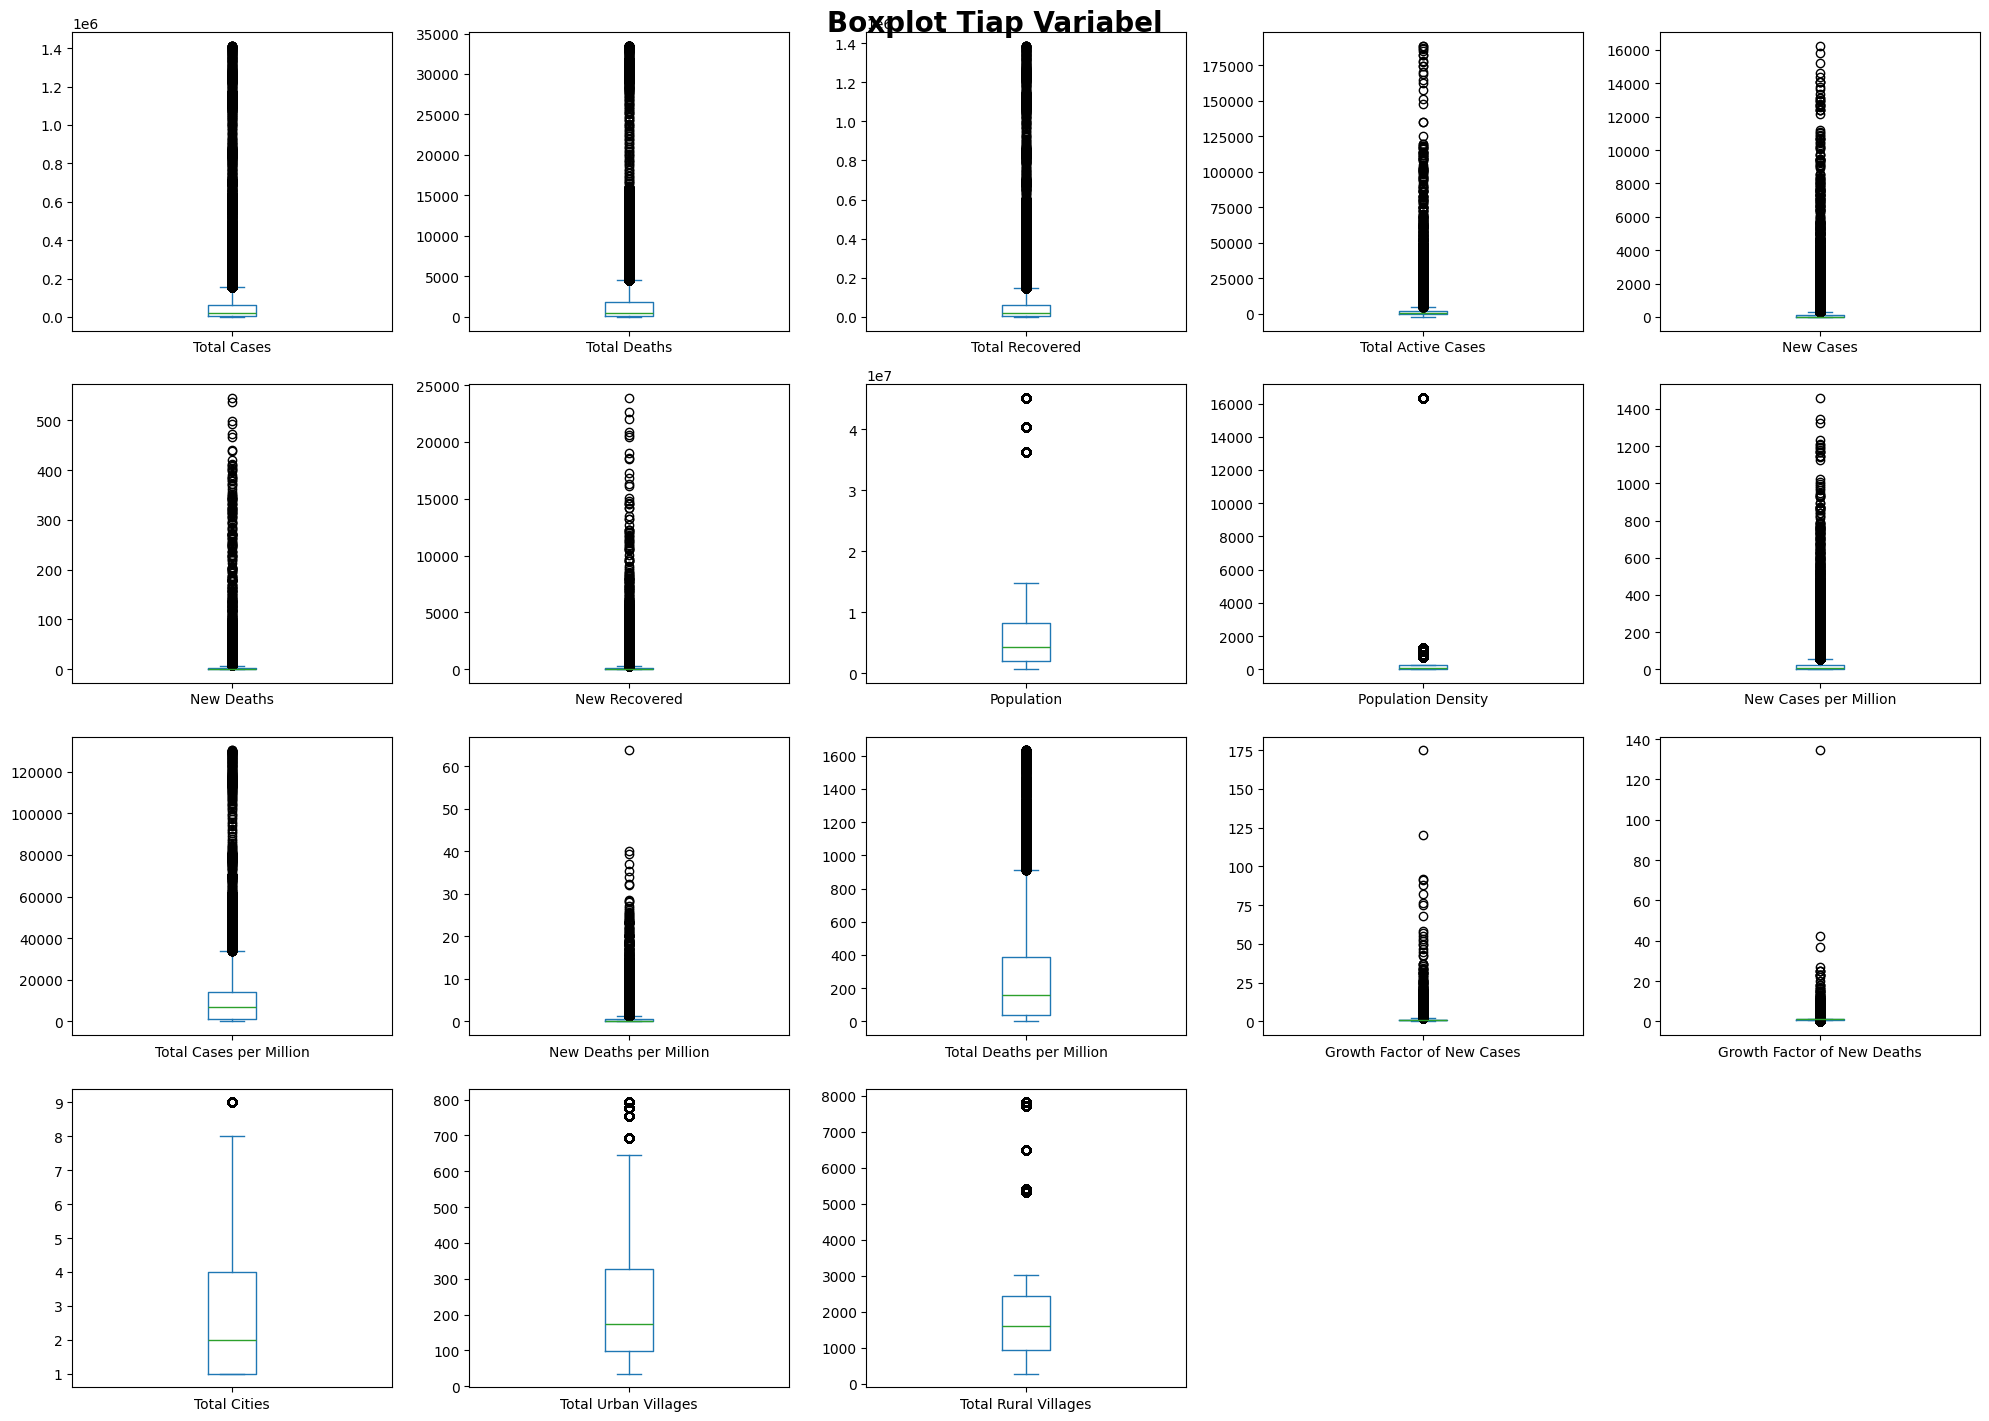

In [ ]:
# Cek Outlier
df[num_cols].plot(
    kind='box',
    subplots=True,
    layout=(7,5),
    figsize=(20,25),
    sharex=False,
    sharey=False
)

plt.suptitle(
    'Boxplot Tiap Variabel',
    fontsize=20,
    fontweight='bold'
)

plt.tight_layout()

plt.show()

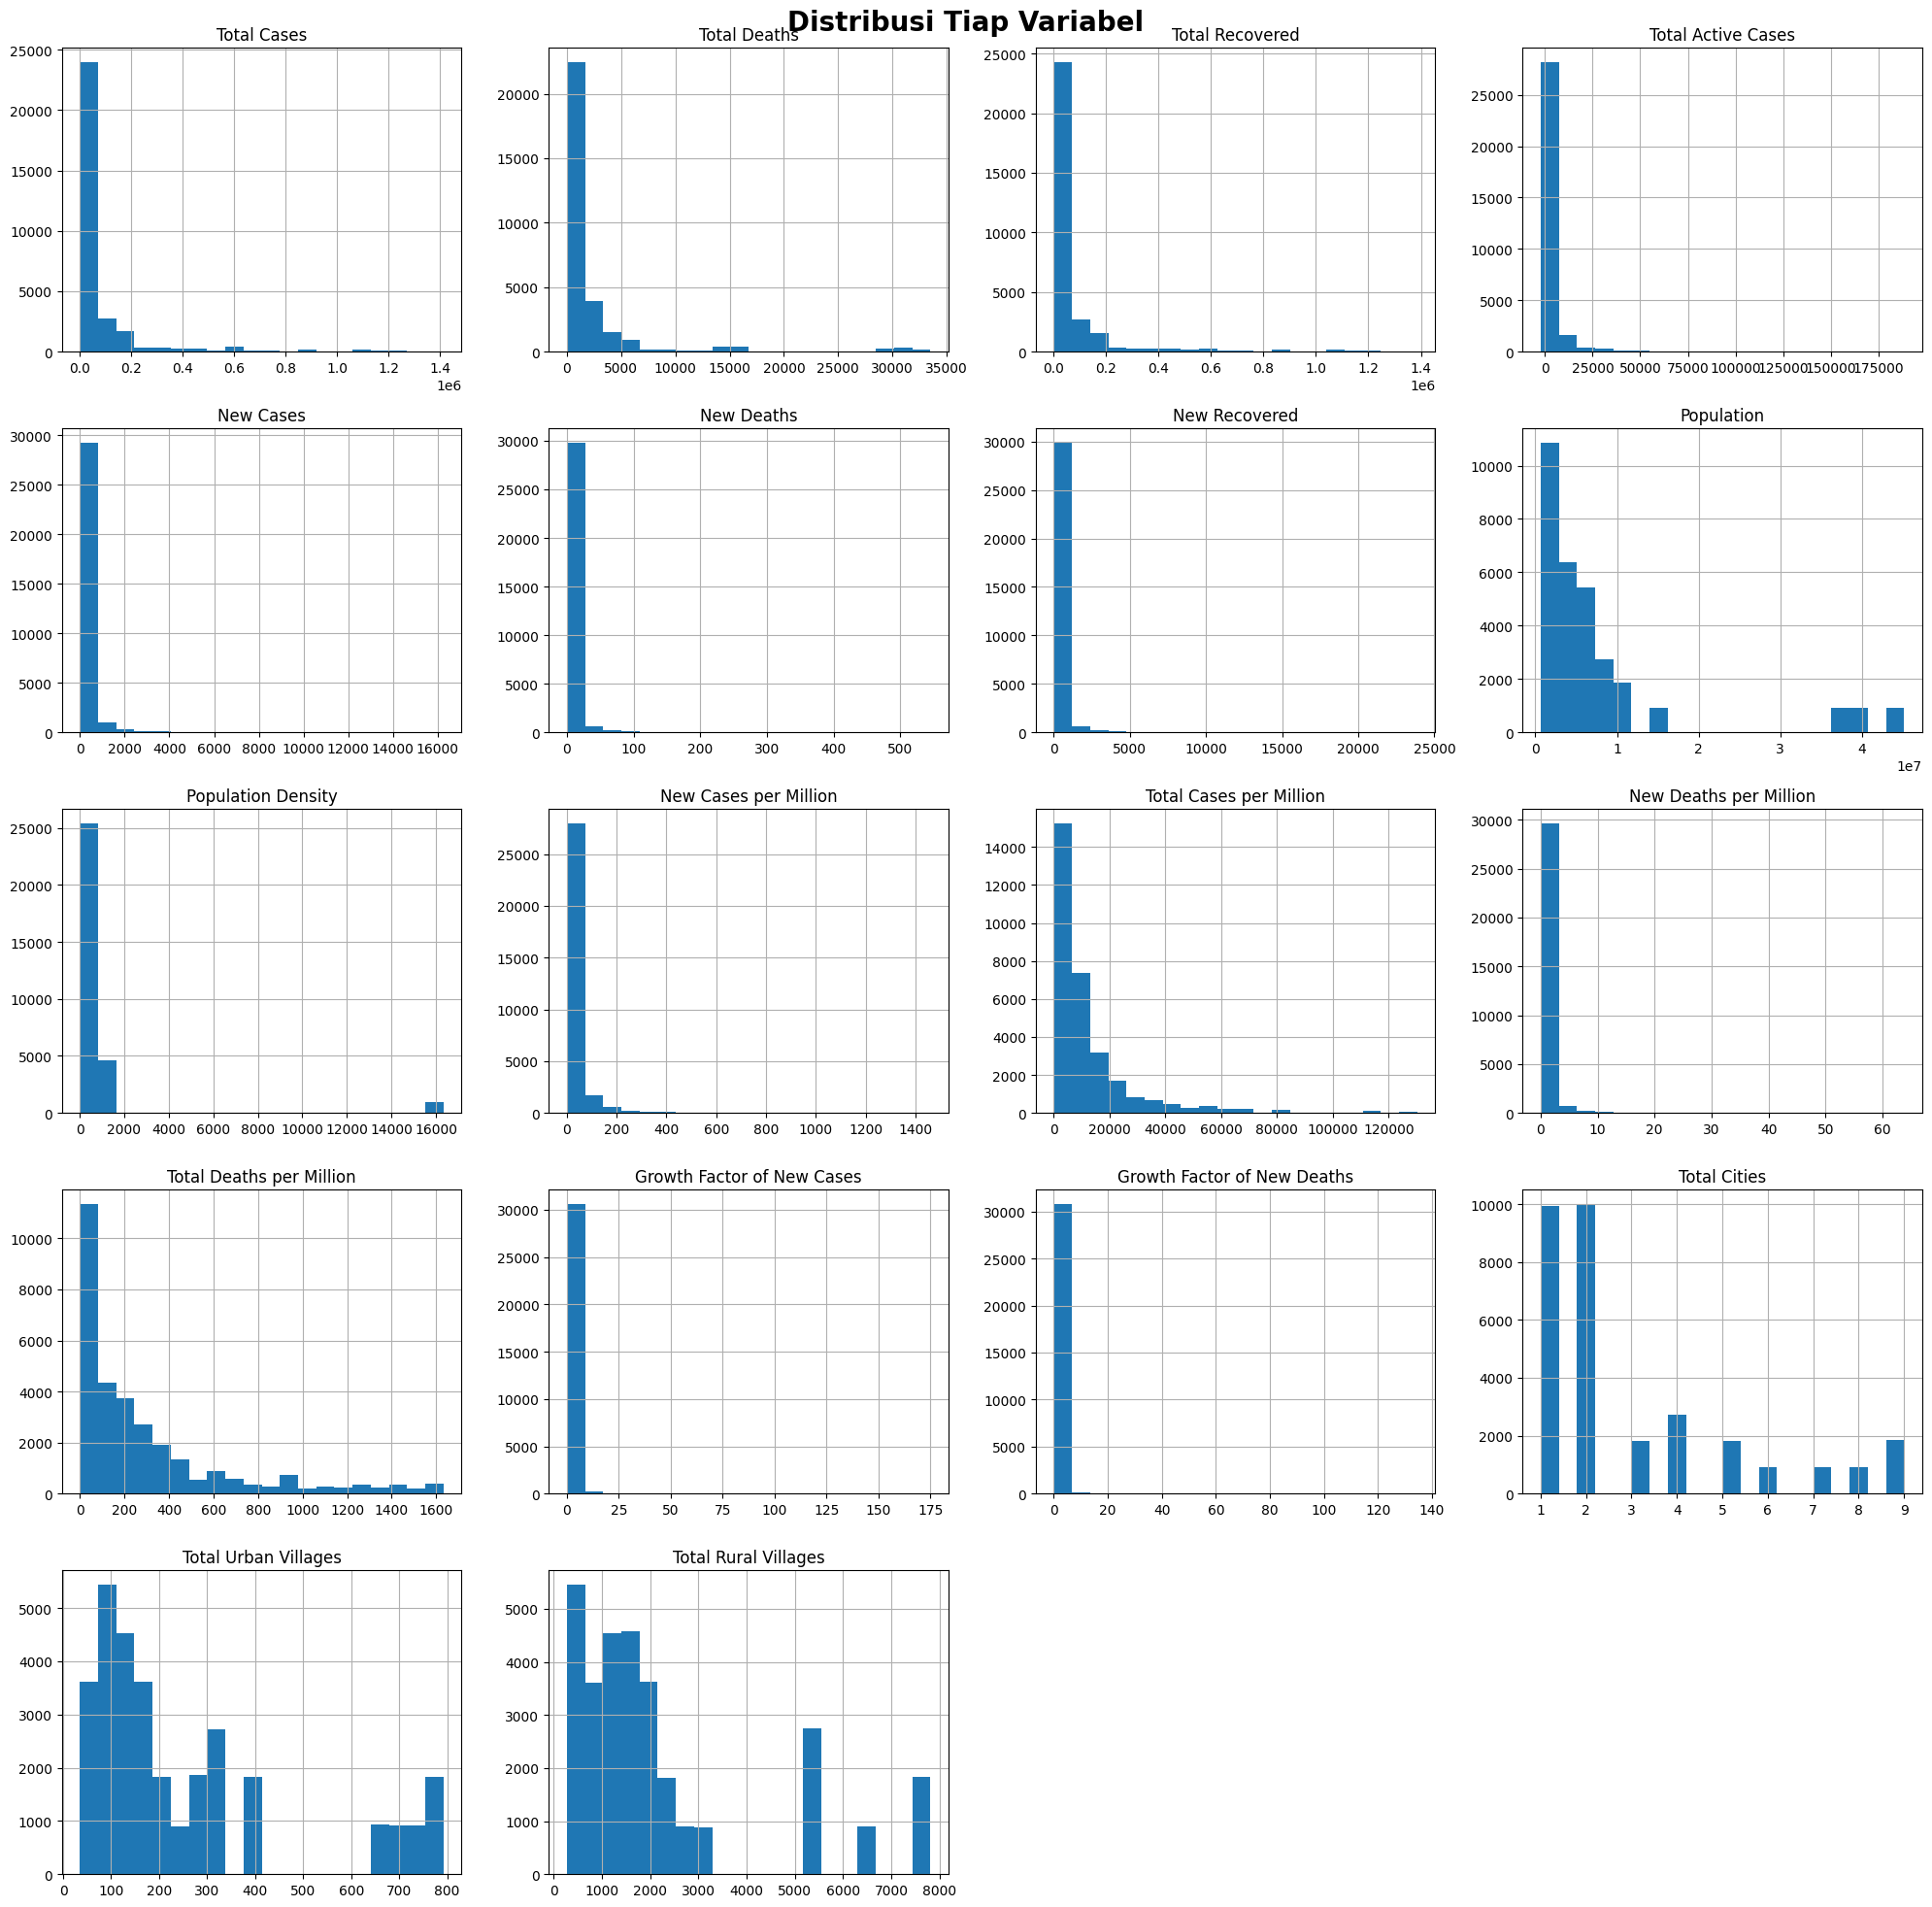

In [ ]:
df[num_cols].hist(
    figsize=(20,20),
    bins=20
)

plt.suptitle(
    'Distribusi Tiap Variabel',
    fontsize=20,
    fontweight='bold'
)

plt.tight_layout()

plt.show()

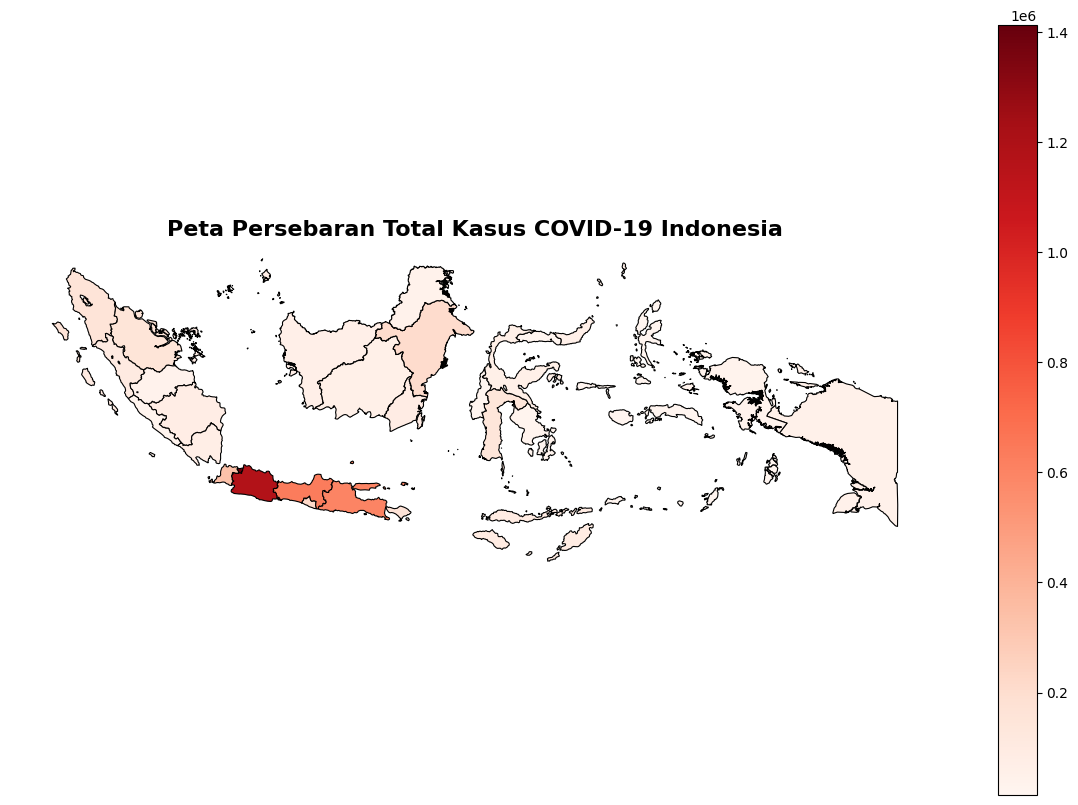

In [ ]:
# Load peta Indonesia
indo_map = gpd.read_file(
    'indonesia-prov.geojson'
)

# Load dataset COVID
df = pd.read_csv(
    'covid_19_indonesia_time_series_all.csv'
)

# Ambil data terbaru tiap provinsi
df['Date'] = pd.to_datetime(df['Date'])

latest_data = df.sort_values('Date').groupby(
    'Location'
).last().reset_index()

# Samakan format nama provinsi
indo_map['Propinsi'] = indo_map['Propinsi'].str.upper()

latest_data['Location'] = latest_data['Location'].str.upper()

# Merge
map_data = indo_map.merge(
    latest_data,
    left_on='Propinsi',
    right_on='Location',
    how='left'
)

# Plot peta
fig, ax = plt.subplots(figsize=(15,10))

map_data.plot(
    column='Total Cases',
    cmap='Reds',
    linewidth=0.8,
    edgecolor='black',
    legend=True,q
    ax=ax
)

plt.title(
    'Peta Persebaran Total Kasus COVID-19 Indonesia',
    fontsize=16,
    fontweight='bold'
)

ax.axis('off')

plt.show()

In [ ]:
df_latest = df.sort_values(
    'Date'
).groupby(
    'Province'
).last().reset_index()

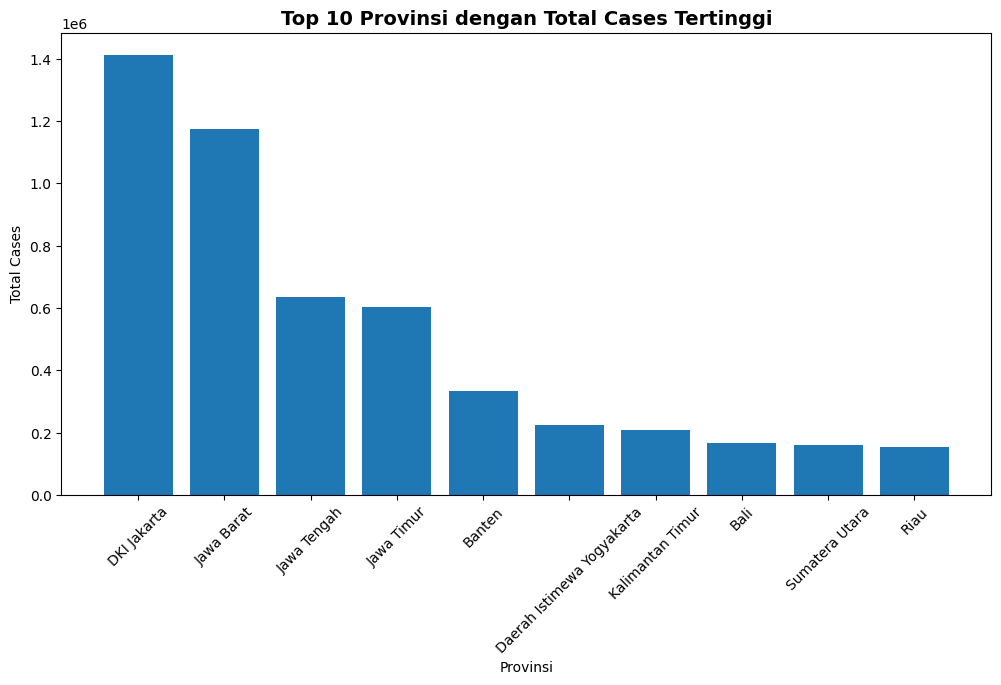

In [ ]:
# Top 10 provinsi kasus tertinggi
top10 = df_latest.nlargest(
    10,
    'Total Cases'
)

plt.figure(figsize=(12,6))

plt.bar(
    top10['Province'],
    top10['Total Cases']
)

plt.title(
    'Top 10 Provinsi dengan Total Cases Tertinggi',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Provinsi')
plt.ylabel('Total Cases')

plt.xticks(rotation=45)

plt.show()

# Preprocessing

In [ ]:
# convert date
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# drop data tanpa koordinat
df = df.dropna(subset=['Latitude', 'Longitude'])

In [ ]:
# urutkan data (penting buat time series)
df = df.sort_values(['Province', 'Date'])
df.head(10)

,Date,Location ISO Code,Location,New Cases,New Deaths,New Recovered,New Active Cases,Total Cases,Total Deaths,Total Recovered,...,Latitude,New Cases per Million,Total Cases per Million,New Deaths per Million,Total Deaths per Million,Total Deaths per 100rb,Case Fatality Rate,Case Recovered Rate,Growth Factor of New Cases,Growth Factor of New Deaths
238,2020-03-26,ID-AC,Aceh,1,0,0,1,1,0,1,...,4.225615,0.19,0.19,0.0,0.0,0.0,0.00%,100.00%,NaN,NaN
263,2020-03-27,ID-AC,Aceh,3,0,0,3,4,0,1,...,4.225615,0.57,0.76,0.0,0.0,0.0,0.00%,25.00%,3.00,1.0
289,2020-03-28,ID-AC,Aceh,1,0,0,1,5,0,1,...,4.225615,0.19,0.95,0.0,0.0,0.0,0.00%,20.00%,0.33,1.0
317,2020-03-29,ID-AC,Aceh,0,0,0,0,5,0,1,...,4.225615,0.00,0.95,0.0,0.0,0.0,0.00%,20.00%,0.00,1.0
346,2020-03-30,ID-AC,Aceh,0,0,0,0,5,0,1,...,4.225615,0.00,0.95,0.0,0.0,0.0,0.00%,20.00%,1.00,1.0
377,2020-03-31,ID-AC,Aceh,0,0,0,0,5,0,1,...,4.225615,0.00,0.95,0.0,0.0,0.0,0.00%,20.00%,1.00,1.0
410,2020-04-01,ID-AC,Aceh,0,0,0,0,5,0,1,...,4.225615,0.00,0.95,0.0,0.0,0.0,0.00%,20.00%,1.00,1.0
443,2020-04-02,ID-AC,Aceh,0,0,0,0,5,0,1,...,4.225615,0.00,0.95,0.0,0.0,0.0,0.00%,20.00%,1.00,1.0
476,2020-04-03,ID-AC,Aceh,0,0,0,0,5,0,1,...,4.225615,0.00,0.95,0.0,0.0,0.0,0.00%,20.00%,1.00,1.0
509,2020-04-04,ID-AC,Aceh,0,0,0,0,5,0,1,...,4.225615,0.00,0.95,0.0,0.0,0.0,0.00%,20.00%,1.00,1.0


In [ ]:
# Handle missing value kolom numerik
for col in num_cols:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

In [ ]:
# Handle missing value kolom kategori
for col in cat_cols:
    if col in df.columns:
        df[col] = df[col].fillna('Unknown')

In [ ]:
df = df.dropna(subset=['Province'])

# Agregasi Data


In [ ]:
df_spatial = df.groupby('Province').agg({
    'Total Cases': 'max',
    'Total Deaths': 'max',
    'Total Recovered': 'max',
    'Latitude': 'mean',
    'Longitude': 'mean'
}).reset_index()

In [ ]:
# Agregasi data terbaru per provinsi

df_latest = df.loc[
    df.groupby('Province')['Date'].idxmax()
].reset_index(drop=True)

df_latest

,Date,Location ISO Code,Location,New Cases,New Deaths,New Recovered,New Active Cases,Total Cases,Total Deaths,Total Recovered,...,New Cases per Million,Total Cases per Million,New Deaths per Million,Total Deaths per Million,Total Deaths per 100rb,Case Fatality Rate,Case Recovered Rate,Growth Factor of New Cases,Growth Factor of New Deaths,Year
0,2022-09-15,ID-AC,Aceh,20,0,1,19,44038,2223,41713,...,3.81,8392.58,0.00,423.65,42.36,5.05%,94.72%,2.50,1.0,2022
1,2022-09-15,ID-BA,Bali,38,1,6,31,166831,4731,161629,...,9.01,39569.32,0.24,1122.11,112.21,2.84%,96.88%,6.33,1.0,2022
2,2022-09-15,ID-BT,Banten,240,0,32,208,333875,2950,328482,...,22.38,31138.16,0.00,275.13,27.51,0.88%,98.38%,1.83,1.0,2022
3,2022-09-15,ID-BE,Bengkulu,4,0,0,4,29173,522,28617,...,2.00,14589.86,0.00,261.06,26.11,1.79%,98.09%,0.50,1.0,2022
4,2022-09-15,ID-JK,DKI Jakarta,1116,0,58,1058,1412511,15513,1386134,...,102.89,130231.62,0.00,1430.28,143.03,1.10%,98.13%,0.91,0.0,2022
5,2022-09-15,ID-YO,Daerah Istimewa Yogyakarta,27,0,0,27,224307,5928,217712,...,7.44,61775.29,0.00,1632.60,163.26,2.64%,97.06%,2.25,1.0,2022
6,2022-09-14,ID-GO,Gorontalo,1,0,0,1,13951,487,13433,...,0.85,11816.36,0.00,412.48,41.25,3.49%,96.29%,1.00,1.0,2022
7,2022-09-15,ID-JA,Jambi,8,0,0,8,38643,889,37681,...,2.29,11061.85,0.00,254.48,25.45,2.30%,97.51%,8.00,1.0,2022
8,2022-09-15,ID-JB,Jawa Barat,492,0,79,413,1173731,15937,1144358,...,10.89,25989.74,0.00,352.89,35.29,1.36%,97.50%,2.58,1.0,2022
9,2022-09-15,ID-JT,Jawa Tengah,108,0,2,106,636409,33489,601517,...,2.97,17501.04,0.00,920.94,92.09,5.26%,94.52%,0.88,0.0,2022


# Pembentukan Bobot Spasial

In [ ]:
geometry = [
    Point(xy) for xy in zip(df_spatial['Longitude'],
                            df_spatial['Latitude'])
]
gdf = gpd.GeoDataFrame(
    df_spatial,
    geometry=geometry,
    crs="EPSG:4326"
)
w = KNN.from_dataframe(gdf, k=4)
w.transform = 'R'

# Analisis Moran's I

In [ ]:
y = gdf['Total Cases']
moran = Moran(y, w)

print("Moran's I :", moran.I)
print("p-value :", moran.p_sim)

Moran's I : 0.4850546913961961
p-value : 0.001


In [ ]:
if moran.p_sim < 0.05:
    print(
        "Terdapat autokorelasi spasial signifikan."
    )
else:
    print(
        "Tidak terdapat autokorelasi spasial signifikan."
    )

Terdapat autokorelasi spasial signifikan.


# Analisis LISA

In [ ]:
lisa = Moran_Local(y, w)
gdf['Significant'] = lisa.p_sim < 0.05
gdf['LISA_Cluster'] = lisa.q

In [ ]:
gdf.loc[
    gdf['Significant'] == False,
    'LISA_Cluster'
] = 0

# Visualisasi

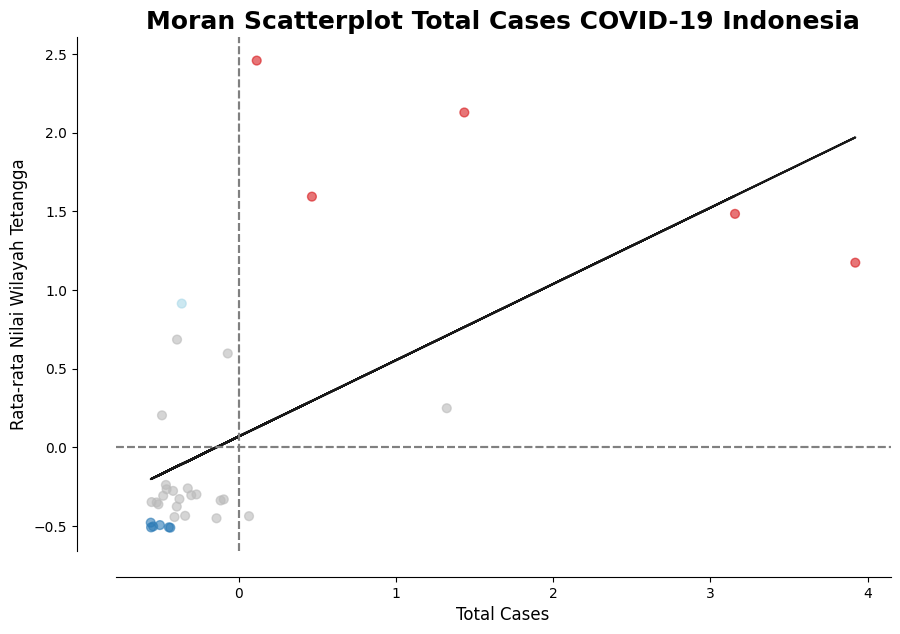

In [ ]:
# Variabel
y = gdf['Total Cases']

# Local Moran
lisa = Moran_Local(y, w)

# Plot
fig, ax = moran_scatterplot(
    lisa,
    p=0.05
)

# Ukuran figure
fig.set_size_inches(10,8)

# Judul
ax.set_title(
    "Moran Scatterplot Total Cases COVID-19 Indonesia",
    fontsize=18,
    fontweight='bold'
)

# Label sumbu
ax.set_xlabel(
    "Total Cases",
    fontsize=12
)

ax.set_ylabel(
    "Rata-rata Nilai Wilayah Tetangga",
    fontsize=12
)

# Garis pembatas kuadran
ax.axhline(0, color='gray', linestyle='--')
ax.axvline(0, color='gray', linestyle='--')

plt.show()

## Peta

In [ ]:
indo_map = gpd.read_file('indonesia-prov.geojson')

In [ ]:
print(indo_map['Propinsi'].unique())

['NUSATENGGARA BARAT' 'GORONTALO' 'SULAWESI TENGGARA'
 'DAERAH ISTIMEWA YOGYAKARTA' 'JAWA TENGAH' 'BANTEN' 'JAWA TIMUR'
 'MALUKU UTARA' 'MALUKU' 'SULAWESI SELATAN' 'DKI JAKARTA' 'JAWA BARAT'
 'PAPUA' 'NUSA TENGGARA TIMUR' 'BALI' 'RIAU' 'KEPULAUAN RIAU'
 'SULAWESI BARAT' 'SULAWESI TENGAH' 'SULAWESI UTARA' 'PAPUA BARAT'
 'SUMATERA UTARA' 'BANGKA BELITUNG' 'SUMATERA BARAT' 'SUMATERA SELATAN'
 'JAMBI' 'LAMPUNG' 'BENGKULU' 'DI. ACEH' 'KALIMANTAN BARAT'
 'KALIMANTAN TENGAH' 'KALIMANTAN SELATAN' 'KALIMANTAN TIMUR'
 'KALIMANTAN UTARA']


In [ ]:
indo_map['Propinsi'] = indo_map[
    'Propinsi'
].str.upper()

gdf['Province'] = gdf[
    'Province'
].str.upper()

In [ ]:
indo_map = indo_map.rename(
    columns={'Propinsi':'Province'}
)

In [ ]:
print(
    set(gdf['Province']) -
    set(indo_map['Province'])
)

{'ACEH', 'KEPULAUAN BANGKA BELITUNG', 'NUSA TENGGARA BARAT'}


In [ ]:
gdf['Province'] = gdf['Province'].replace({
    'KEPULAUAN BANGKA BELITUNG': 'BANGKA BELITUNG',
    'ACEH': 'DI. ACEH',
    'NUSA TENGGARA BARAT': 'NUSATENGGARA BARAT'
})

In [ ]:
print(
    set(gdf['Province']) -
    set(indo_map['Province'])
)

set()


In [ ]:
gdf['LISA_Cluster'] = lisa.q

In [ ]:
# Variabel
y = gdf['Total Cases']

# Hitung LISA
lisa = Moran_Local(y, w)

In [ ]:
cluster_labels = {
    1: 'High-High',
    2: 'Low-High',
    3: 'Low-Low',
    4: 'High-Low'
}

gdf['LISA_Cluster'] = gdf[
    'LISA_Cluster'
].map(cluster_labels)

In [ ]:
map_data = indo_map.merge(
    gdf,
    on='Province',
    how='left'
)

In [ ]:
map_data = gpd.GeoDataFrame(
    map_data,
    geometry='geometry_x'
)

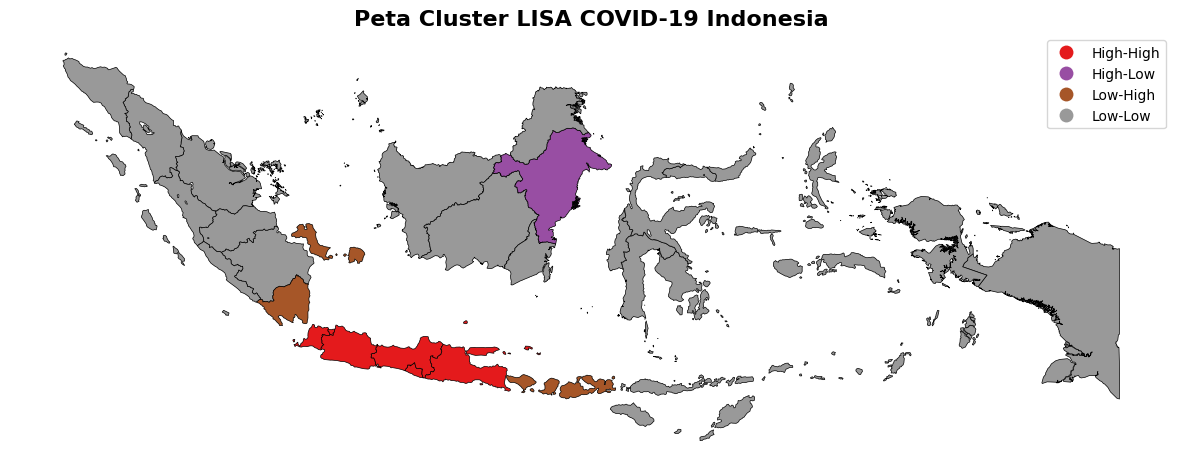

In [ ]:
fig, ax = plt.subplots(figsize=(15,10))

map_data.plot(
    column='LISA_Cluster',
    categorical=True,
    legend=True,
    cmap='Set1',
    edgecolor='black',
    linewidth=0.5,
    ax=ax
)

plt.title(
    'Peta Cluster LISA COVID-19 Indonesia',
    fontsize=16,
    fontweight='bold'
)

ax.axis('off')

plt.show()

In [ ]:
gdf[['Province','LISA_Cluster']]

,Province,LISA_Cluster
0,DI. ACEH,Low-Low
1,BALI,Low-High
2,BANTEN,High-High
3,BENGKULU,Low-Low
4,DKI JAKARTA,High-High
5,DAERAH ISTIMEWA YOGYAKARTA,High-High
6,GORONTALO,Low-Low
7,JAMBI,Low-Low
8,JAWA BARAT,High-High
9,JAWA TENGAH,High-High


# Feature Importance

In [ ]:
feature_cols = [
    'Population',
    'Population Density',
    'Area (km2)',
    'Total Cities',
    'Total Districts',
    'Total Urban Villages',
    'Total Rural Villages'
]

corr_feature = df_latest[
    feature_cols + ['Total Cases']
].corr()

print(corr_feature['Total Cases'].sort_values(
    ascending=False
))

Total Cases             1.000000
Population Density      0.755870
Population              0.711029
Total Cities            0.610932
Total Urban Villages    0.474529
Total Rural Villages    0.373665
Total Districts         0.373549
Area (km2)             -0.198261
Name: Total Cases, dtype: float64


In [ ]:
feature_importance = corr_feature[
    'Total Cases'
].sort_values(
    ascending=False
)

feature_importance = feature_importance.drop(
    'Total Cases'
)

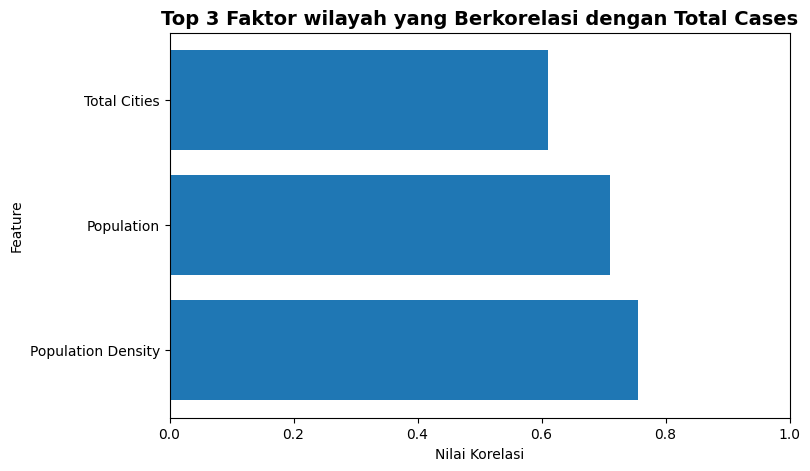

In [ ]:
top_features = feature_importance.head(3)

plt.figure(figsize=(8,5))

plt.barh(
    top_features.index,
    top_features.values
)

plt.title(
    'Top 3 Faktor wilayah yang Berkorelasi dengan Total Cases',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Nilai Korelasi')
plt.ylabel('Feature')

plt.xlim(0,1)

plt.show()

# Analisis Lanjutan

**Analisis Jumlah Kematian COVID-19 per Tahun**

In [ ]:
# Convert tanggal
df['Date'] = pd.to_datetime(df['Date'])

# Ambil tahun
df['Year'] = df['Date'].dt.year

# Agregasi jumlah kematian per tahun
death_per_year = df.groupby(
    'Year'
)['New Deaths'].sum().reset_index()

print(death_per_year)

   Year  New Deaths
0  2020       22993
1  2021      121143
2  2022       13683


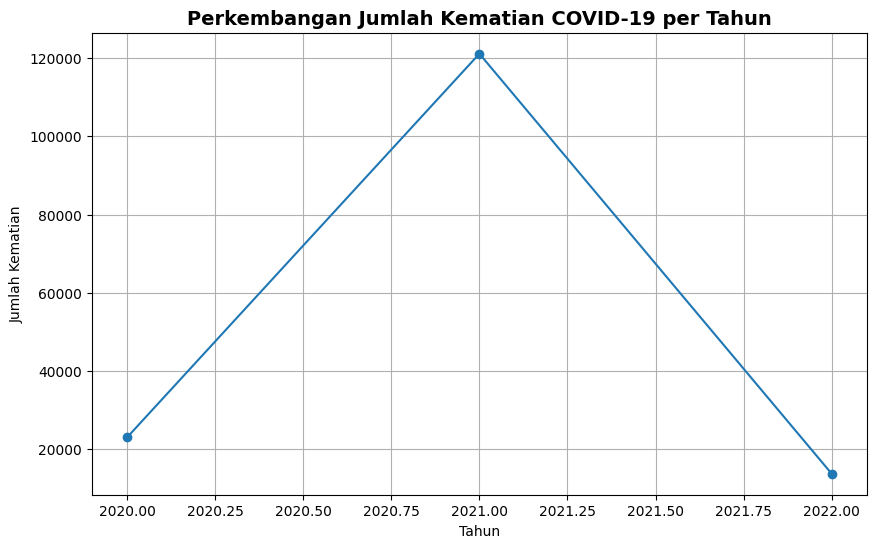

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(
    death_per_year['Year'],
    death_per_year['New Deaths'],
    marker='o'
)

plt.title(
    'Perkembangan Jumlah Kematian COVID-19 per Tahun',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Tahun')
plt.ylabel('Jumlah Kematian')

plt.grid(True)

plt.show()

**Perbandingan New Cases dan Case Recovered Rate**

In [ ]:

df['Case Recovered Rate'] = df[
    'Case Recovered Rate'
].astype(str)

df['Case Recovered Rate'] = df[
    'Case Recovered Rate'
].str.replace('%','')

df['Case Recovered Rate'] = pd.to_numeric(
    df['Case Recovered Rate'],
    errors='coerce'
)

# Agregasi per tahun
time_series = df.groupby('Year').agg({
    'New Cases':'sum',
    'Case Recovered Rate':'mean'
}).reset_index()

print(time_series)

   Year  New Cases  Case Recovered Rate
0  2020     750848            77.808349
1  2021    3511801            88.284088
2  2022    2134660            95.631187


**Tren New Cases dan Case Recovered Rate**

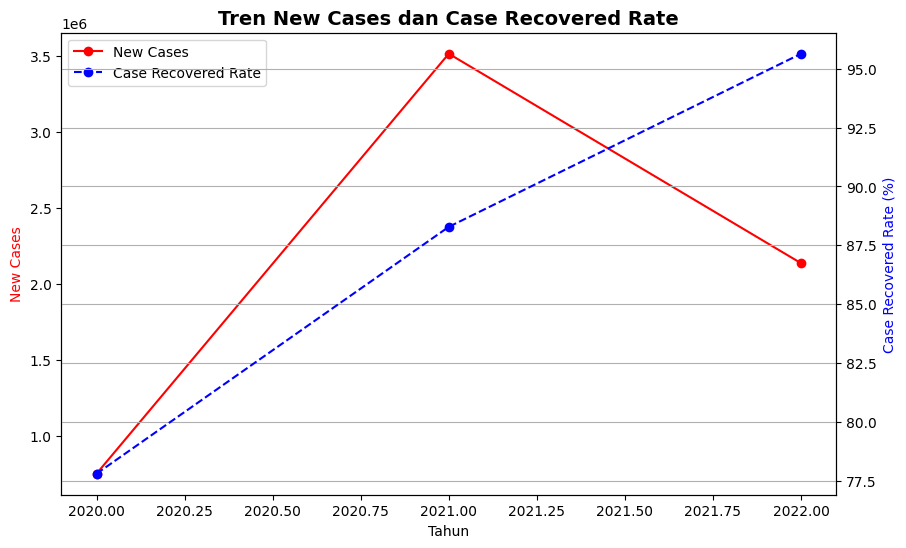

In [ ]:
fig, ax1 = plt.subplots(figsize=(10,6))

# New Cases
ax1.plot(
    time_series['Year'],
    time_series['New Cases'],
    marker='o',
    color='red',
    label='New Cases'
)

ax1.set_xlabel('Tahun')

ax1.set_ylabel(
    'New Cases',
    color='red'
)

# Axis kedua
ax2 = ax1.twinx()

# Recovery Rate
ax2.plot(
    time_series['Year'],
    time_series['Case Recovered Rate'],
    marker='o',
    linestyle='--',
    color='blue',
    label='Case Recovered Rate'
)

ax2.set_ylabel(
    'Case Recovered Rate (%)',
    color='blue'
)

# Legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc='upper left'
)

plt.title(
    'Tren New Cases dan Case Recovered Rate',
    fontsize=14,
    fontweight='bold'
)

plt.grid(True)

plt.show()

**Perbandingan New Cases vs New Deaths per Tahun**

In [ ]:
# Agregasi per tahun
covid_trend = df.groupby('Year').agg({
    'New Cases':'sum',
    'New Deaths':'sum'
}).reset_index()

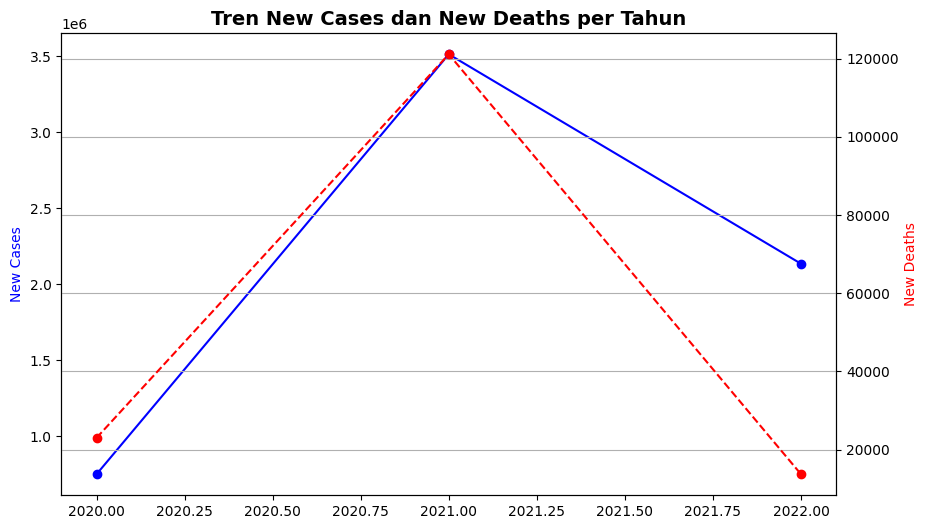

In [ ]:
fig, ax1 = plt.subplots(figsize=(10,6))

# New Cases
ax1.plot(
    covid_trend['Year'],
    covid_trend['New Cases'],
    marker='o',
    color='blue',
    label='New Cases'
)

ax1.set_ylabel(
    'New Cases',
    color='blue'
)

# Axis kedua
ax2 = ax1.twinx()

# New Deaths
ax2.plot(
    covid_trend['Year'],
    covid_trend['New Deaths'],
    marker='o',
    linestyle='--',
    color='red',
    label='New Deaths'
)

ax2.set_ylabel(
    'New Deaths',
    color='red'
)

plt.title(
    'Tren New Cases dan New Deaths per Tahun',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Tahun')

plt.grid(True)

plt.show()

**Analisis Population Density**

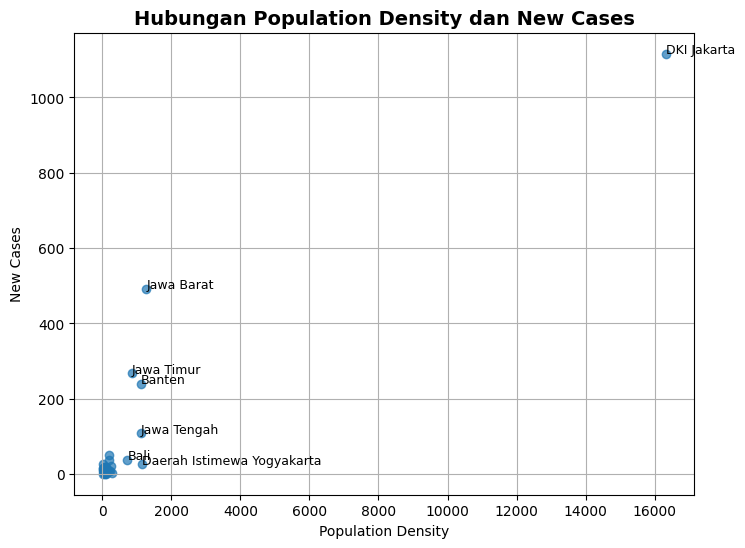

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df_latest['Population Density'],
    df_latest['New Cases'],
    alpha=0.7
)

# Highlight provinsi ekstrem
top = df_latest.nlargest(
    7,
    'Population Density'
)

for _, row in top.iterrows():
    plt.text(
        row['Population Density'],
        row['New Cases'],
        row['Province'],
        fontsize=9
    )

plt.title(
    'Hubungan Population Density dan New Cases',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Population Density')
plt.ylabel('New Cases')

plt.grid(True)

plt.show()